In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw shapes:", x_train.shape, y_train.shape)

PIXEL_MAX = 255.0
x_train = x_train / PIXEL_MAX
x_test  = x_test  / PIXEL_MAX

TIME_STEPS = 28
FEATURES   = 28
x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test  = x_test.reshape((x_test.shape[0],  TIME_STEPS, FEATURES))

NUM_CLASSES = 10
y_train = to_categorical(y_train, NUM_CLASSES)
y_test  = to_categorical(y_test,  NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

raw shapes: (60000, 28, 28) (60000,)
prepared: (60000, 28, 28) (60000, 10)


In [ ]:
assert x_train.max() <= 1.0 and x_train.min() >= 0.0, "pixels not in [0,1]"
assert x_train.shape[1:] == (28, 28), "sequence shape should be (28, 28)"
assert y_train.shape[1] == 10, "labels should be one-hot with 10 columns"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [ ]:
model = models.Sequential()

LSTM_UNITS = 64
model.add(layers.LSTM(LSTM_UNITS,
                      activation='relu',
                      input_shape=(TIME_STEPS, FEATURES)))

OUT_UNITS = 10
model.add(layers.Dense(OUT_UNITS, activation='softmax'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        23,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,458 (95.54 KB)

 Trainable params: 24,458 (95.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=5,
                    batch_size=64,
                    validation_data=(x_test, y_test))

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.7767 - loss: 0.6809 - val_accuracy: 0.9346 - val_loss: 0.2067
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9465 - loss: 0.1760 - val_accuracy: 0.9569 - val_loss: 0.1286
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9613 - loss: 0.1277 - val_accuracy: 0.9680 - val_loss: 0.0958
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9689 - loss: 0.1016 - val_accuracy: 0.9709 - val_loss: 0.0901
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9737 - loss: 0.0864 - val_accuracy: 0.9783 - val_loss: 0.0700
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9783 - loss: 0.0700
Test accuracy: 97.83%


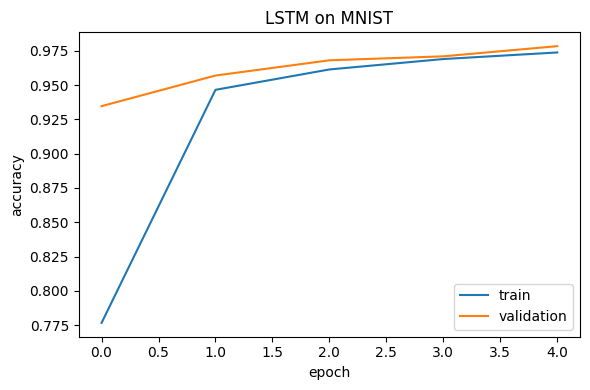

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('LSTM on MNIST')
plt.tight_layout(); plt.show()